In [ ]:
%pip install ipykernel
%pip install opencv-python 
%pip install matplotlib
%pip install plotly nbformat

In [35]:
import cv2 as cv 
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import cm, colors

In [36]:
#TC001 
#Connect to the camera using OpenCV

camera_index = 0  # Change this to the appropriate index for your camera

cap = cv.VideoCapture(camera_index)

if not cap.isOpened():
    print("Error: Could not open camera.")

# Get camera properties
print("Frame Width:", cap.get(cv.CAP_PROP_FRAME_WIDTH))
print("Frame Height:", cap.get(cv.CAP_PROP_FRAME_HEIGHT))
print("FPS:", cap.get(cv.CAP_PROP_FPS))
print("Total FPS:", cap.get(cv.CAP_PROP_FRAME_COUNT)/cap.get(cv.CAP_PROP_FPS))

print(cap.get(cv.CAP_PROP_POS_FRAMES))  # Current frame position
print("Current Position (ms):", cap.get(cv.CAP_PROP_POS_MSEC))  # Current position in milliseconds


Error: Could not open camera.
Frame Width: -1.0
Frame Height: -1.0
FPS: -1.0
Total FPS: 1.0
-1.0
Current Position (ms): -1.0


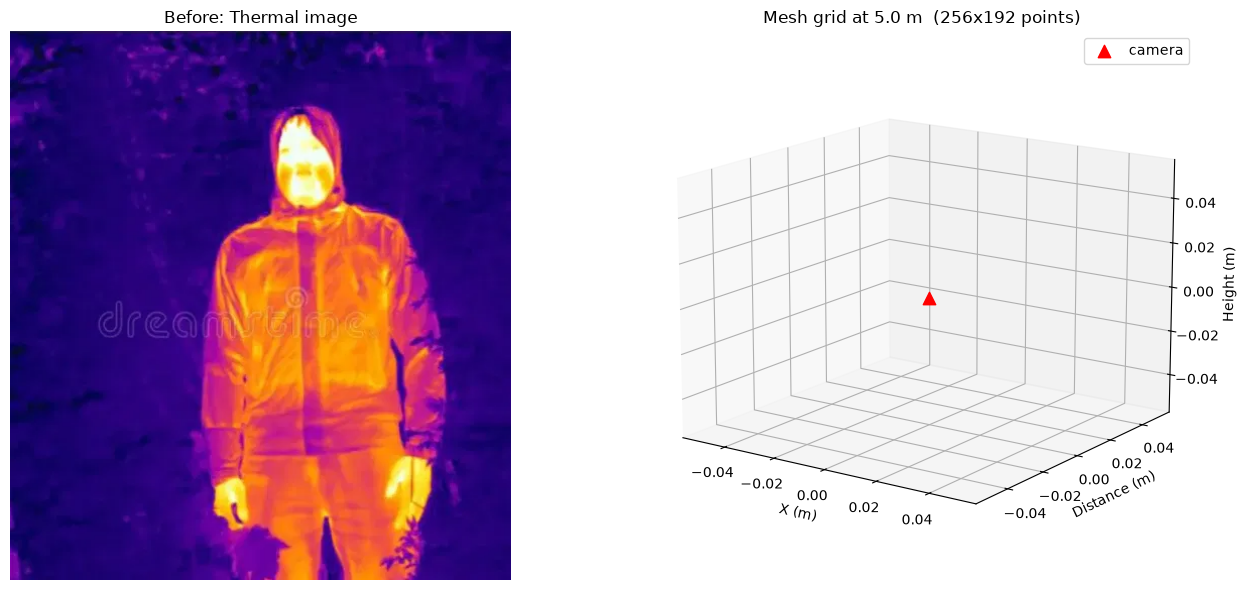

In [ ]:
#Define Width and Height image Capture
cam_width = 256
cam_height = 192

cap.set(cv.CAP_PROP_FRAME_WIDTH, cam_width)
cap.set(cv.CAP_PROP_FRAME_HEIGHT, cam_height)


#Config
cam_default_distance = 5.0 #5 meters 16 feet 

#Cam Width and Height
HFOV_DEG = 56.0
VFOV_DEG = 42.0

#Mesh Downsampling
mesh_downsample_factor = 1  # Downsample factor for the mesh grid
TEMP_RANGE = (20, 40)  # Temperature range in Celsius
image_path = "thermal_image.png"  # Path to the thermal image file

#Image
img = cv.imread(image_path)

#Convert image into data array

#Higher heat + larger area = closer to 0 m 
#Higher heat + smaller area = closer to 1 m 

#Meshgrid generation
fx = (cam_width / 2) / np.tan(np.radians(HFOV_DEG / 2))     # focal length in pixels (horizontal)
fy = (cam_height / 2) / np.tan(np.radians(VFOV_DEG / 2))    # focal length in pixels (vertical)

# pixel grid: u = column, v = row of every pixel
u, v = np.meshgrid(np.arange(cam_width), np.arange(cam_height))

# pixels -> metres at cam_default_distance
X = cam_default_distance * (u - (cam_width - 1) / 2) / fx       # left / right (m)
Z = -cam_default_distance * (v - (cam_height - 1) / 2) / fy     # up / down (m)
Y = np.full_like(X, cam_default_distance, dtype=float)          # distance (m)

# Display: left = image, right = mesh grid
fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1)
ax1.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
ax1.set_title("Before: Thermal image")
ax1.axis("off")

ax2 = fig.add_subplot(1, 2, 2, projection="3d")

ax2.scatter([0], [0], [0], c="red", s=80, marker="^", label="camera")                   # camera at origin
ax2.set_xlabel("X (m)"); ax2.set_ylabel("Distance (m)"); ax2.set_zlabel("Height (m)")
ax2.set_title(f"Mesh grid at {cam_default_distance} m  ({cam_width}x{cam_height} points)")
ax2.view_init(elev=15, azim=-55); ax2.legend()

plt.tight_layout()
plt.show()

In [ ]:
#Send ESP
 
 
 
 
 